# Support vector machines

Linear SVMs on all three representations (token indicators, bag of words, averaged GloVe embeddings), evaluated like the other models: 5-fold cross-validation on SST-2 train with parent folds, then the validation split.

A linear SVM is the same kind of model as the log-linear one with a different loss, so it is a fair comparison on any representation. It uses scikit-learn's default `C=1`, which was not tuned. An RBF kernel was considered, but an exact kernel SVM needs minutes per fold on about 52k rows and, in a quick test on a subsample, was not better than the linear SVM on the sparse token features, so it is not run here.

In [1]:
TOKENIZERS = ["nltk", "bpe_500", "bpe_2000", "bpe_8000", "bpe_20000"]
  # GloVe vectors exist for words only, so the GloVe systems only run with the nltk tokenizer
SVM_KERNELS = {         # kernel -> representations it is run on
    "linear": ["indicator", "bow", "glove"],
}
SEEDS = [0]             # one cross-validation run per seed, e.g. [0, 3, 5]
K = 5                   # number of folds
MIN_WORDS = 1           # keep every train example (parent folds need all rows)
CV = "parents"          # "parents": leak-free folds of whole parent sentences; "random": plain random folds
SUFFIX = "" if CV == "random" else "_parents"  # appended to the names of the saved results
SVM_ARGS = dict(C=1.0, gamma="scale")  # scikit-learn defaults, not tuned (gamma is only used by an RBF kernel, which is not run)
RECOMPUTE = False       # True: ignore saved results and recompute everything
ROPE = 0.005            # two systems count as practically equivalent if their mean accuracy differs by less than this

In [2]:
import warnings
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd

import cv_helpers as cv
from tokenized_data import load

## Cross-validation
Parent folds: the held-out fold is a random set of whole parent sentences, and every training row that is equal to, or inside, one of them is removed from that fold's training data (see `data_analysis.ipynb`).

**Representations.** `indicator` and `bow` are the sparse token features. `glove` is the mean of the GloVe embeddings (6B tokens, 300 dimensions; Pennington, Socher & Manning, 2014) of a sentence's NLTK tokens, standardised with the mean and spread of the training rows. Finished runs are reused from `results/` unless `RECOMPUTE = True`.

In [3]:
# raw sentences of the train rows (the same for every tokenizer), used to find the parent sentences
raw_train_text = load("bpe_500")[0]["train"].text.tolist()

def get_folds(y, seed):
    if CV == "parents":
        assert MIN_WORDS == 1, "parent folds use all train rows"
        return cv.parent_folds(raw_train_text, y, K, seed)
    return cv.make_folds(y, K, seed)

results = {}
n_examples = {}

for tok_name in TOKENIZERS:
    splits, tokenizer = load(tok_name)
    train = splits["train"]
    train = train[train.text.str.split().str.len() >= MIN_WORDS]
    y = train.label.to_numpy()
    print(f"{tok_name}: {len(train)} examples, vocabulary {tokenizer.get_vocab_size()}")
    n_examples[tok_name] = len(train)

    for kernel, kernel_features in SVM_KERNELS.items():
        for features in cv.features_for(tok_name, kernel_features):
            name = f"svm_{kernel}_{features}_{tok_name}{SUFFIX}"
            info = dict(tokenizer=tok_name, model=f"svm_{kernel}", features=features, seeds=SEEDS, k=K,
                        min_words=MIN_WORDS, cv=CV, svm_args=SVM_ARGS)
            accuracies = None if RECOMPUTE else cv.cached_results(name, **info)
            if accuracies is None:
                X, scale = cv.build_features(train, tokenizer, features)
                accuracies = [cv.cv_svm(X, y, get_folds(y, seed), kernel=kernel, scale=scale, **SVM_ARGS) for seed in SEEDS]
                cv.save_results(name, accuracies, **info)
            else:
                print(f"  {kernel} / {features}: saved results")
            results[(tok_name, kernel, features)] = np.array(accuracies)  # shape [seeds, folds]

nltk: 67349 examples, vocabulary 14802
  linear / indicator: saved results
  linear / bow: saved results
  linear / glove: saved results


bpe_500: 67349 examples, vocabulary 500
  linear / indicator: saved results
  linear / bow: saved results


bpe_2000: 67349 examples, vocabulary 2000
  linear / indicator: saved results
  linear / bow: saved results


bpe_8000: 67349 examples, vocabulary 8000
  linear / indicator: saved results
  linear / bow: saved results


bpe_20000: 67349 examples, vocabulary 20000
  linear / indicator: saved results
  linear / bow: saved results


## Results

In [4]:
pd.DataFrame([
    {"tokenizer": t, "kernel": k, "features": f, "mean accuracy": a.mean(), "std": a.std(), "scores": a.size}
    for (t, k, f), a in results.items()
]).round(4)

,tokenizer,kernel,features,mean accuracy,std,scores
0,nltk,linear,indicator,0.7887,0.0118,5
1,nltk,linear,bow,0.7878,0.0082,5
2,nltk,linear,glove,0.7872,0.0094,5
3,bpe_500,linear,indicator,0.7115,0.0119,5
4,bpe_500,linear,bow,0.7120,0.0122,5
5,bpe_2000,linear,indicator,0.7683,0.0082,5
6,bpe_2000,linear,bow,0.7659,0.0052,5
7,bpe_8000,linear,indicator,0.7808,0.0093,5
8,bpe_8000,linear,bow,0.7766,0.0129,5
9,bpe_20000,linear,indicator,0.7824,0.0090,5


## Fold accuracies
Accuracy of every SVM system on each cross-validation fold.

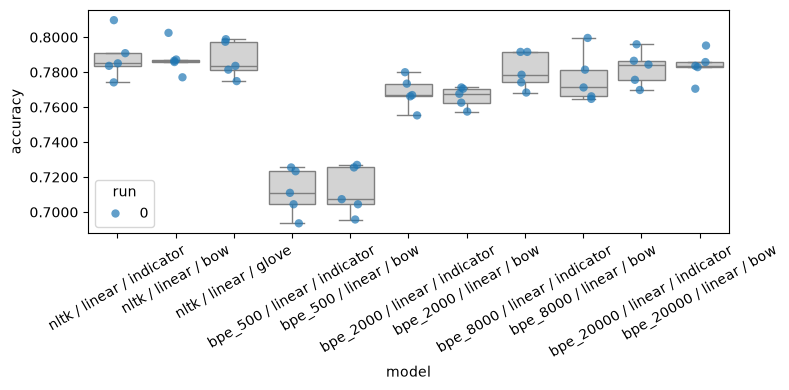

In [5]:
from from_tutorial import analysis

scores = pd.DataFrame([
    {"model": f"{t} / {kernel} / {f}", "accuracy": acc, "run": run, "fold": fold}
    for (t, kernel, f), accs in results.items()
    for run, row in enumerate(accs)
    for fold, acc in enumerate(row)
])
analysis.plot_box_and_points(scores)

## Evaluation on the validation split
Each SVM is trained once on all of train and scored once on the SST-2 validation split (whole sentences that never appear in train), next to its cross-validation score. Validation accuracies are cached in `results/`.

In [6]:
def mean_cv(name):
    try:
        return cv.load_results(name).mean()
    except FileNotFoundError:
        return float("nan")

rows = []
for tok_name in TOKENIZERS:
    splits, tokenizer = load(tok_name)
    train = splits["train"]
    train = train[train.text.str.split().str.len() >= MIN_WORDS]
    validation = splits["validation"]
    y_train, y_val = train.label.to_numpy(), validation.label.to_numpy()

    for kernel, kernel_features in SVM_KERNELS.items():
        for features in cv.features_for(tok_name, kernel_features):
            name = f"svm_{kernel}_{features}_{tok_name}"
            try:
                validation_accuracy = cv.load_results(name + "_validation").item()   # cached
            except FileNotFoundError:
                X_train, scale = cv.build_features(train, tokenizer, features)
                X_val, _ = cv.build_features(validation, tokenizer, features)
                validation_accuracy = cv.eval_svm(X_train, y_train, X_val, y_val, kernel=kernel, scale=scale, **SVM_ARGS)
                cv.save_results(name + "_validation", [[validation_accuracy]], tokenizer=tok_name, model=f"svm_{kernel}",
                                features=features, min_words=MIN_WORDS, svm_args=SVM_ARGS)
            rows.append({"tokenizer": tok_name, "kernel": kernel, "features": features,
                         "cv parent folds": mean_cv(name + "_parents"), "validation": validation_accuracy})

table = pd.DataFrame(rows)
table["gap parents"] = table["cv parent folds"] - table["validation"]
print(f"majority-class baseline on validation: {max(y_val.mean(), 1 - y_val.mean()):.4f}")
table.round(4)

majority-class baseline on validation: 0.5092


,tokenizer,kernel,features,cv parent folds,validation,gap parents
0,nltk,linear,indicator,0.7887,0.8211,-0.0324
1,nltk,linear,bow,0.7878,0.8222,-0.0344
2,nltk,linear,glove,0.7872,0.7821,0.0051
3,bpe_500,linear,indicator,0.7115,0.7454,-0.0339
4,bpe_500,linear,bow,0.7120,0.7328,-0.0208
5,bpe_2000,linear,indicator,0.7683,0.7798,-0.0115
6,bpe_2000,linear,bow,0.7659,0.7821,-0.0162
7,bpe_8000,linear,indicator,0.7808,0.7924,-0.0116
8,bpe_8000,linear,bow,0.7766,0.7970,-0.0204
9,bpe_20000,linear,indicator,0.7824,0.8073,-0.0249


## All systems on the NLTK tokenizer
Mean accuracy of every architecture and representation, from the saved results: cross-validation with parent folds, and the validation split. `NaN` means that combination was not run or its notebook has not been run yet.

In [7]:
models = ["loglinear", "mlp", "svm_linear"]
representations = ["indicator", "bow", "glove"]

def saved_mean(name):
    try:
        return cv.load_results(name).mean()
    except FileNotFoundError:
        return float("nan")

cv_table = pd.DataFrame({f: {m: saved_mean(f"{m}_{f}_nltk_parents") for m in models} for f in representations})
val_table = pd.DataFrame({f: {m: saved_mean(f"{m}_{f}_nltk_validation") for m in models} for f in representations})
pd.concat({"cross-validation (parent folds)": cv_table, "validation split": val_table}, axis=1).round(4)

cross-validation (parent folds)                 validation split  \
                                 indicator     bow   glove        indicator   
loglinear                           0.8089  0.8083  0.7866           0.8142   
mlp                                 0.8109  0.8081  0.7884           0.8211   
svm_linear                          0.7887  0.7878  0.7872           0.8211   

                            
               bow   glove  
loglinear   0.8085  0.7810  
mlp         0.8280  0.7752  
svm_linear  0.8222  0.7821